# Séance 6 - Manipuler des données avec `pandas`

Thomas Thivillon

2026-11-25

Cette séance est entièrement consacrée à `pandas`, la librairie de référence pour manipuler des **données tabulaires** (des tableaux avec des observations en lignes et des variables en colonnes).

**Objectifs de la séance.** À la fin du TP, vous devez savoir :

1. créer et explorer un `DataFrame` (dimensions, types, statistiques descriptives) ;
2. sélectionner des lignes et des colonnes (`[]`, `loc`, `iloc`, filtres booléens, `query`) ;
3. créer, renommer, supprimer et transformer des variables ; trier un tableau ;
4. repérer et traiter les valeurs manquantes ;
5. calculer des statistiques par groupe (`groupby`, `agg`, tableaux croisés) ;
6. assembler plusieurs tableaux (`concat`, `merge`).


| Partie | Contenu | Durée |
|---|---|---|
| 1 | Séries et DataFrames : les structures de `pandas` | 10 min |
| 2 | Importer et explorer un jeu de données | 10 min |
| 3 | Sélectionner et filtrer + exercice 1 | 20 min |
| 4 | Créer et transformer des variables + exercice 2 | 15 min |
| 5 | Valeurs manquantes | 5 min |
| 6 | Statistiques par groupe + exercice 3 | 15 min |
| 7 | Concaténer et joindre des tableaux + exercice 4 | 10 min |
| 8 | Un mot sur les graphiques | 5 min |
| – | Exercice de synthèse (à finir chez soi si besoin) | – |

**Références.** Ce TP s'appuie sur le chapitre 10 de *Python pour les économistes* (E. Gallic) et sur les chapitres de Lino Galiana : [introduction à pandas](https://pythonds.linogaliana.fr/content/manipulation/02_pandas_intro.html), [statistiques par groupe](https://pythonds.linogaliana.fr/content/manipulation/02_pandas_stats.html) et [jointures](https://pythonds.linogaliana.fr/content/manipulation/02_pandas_joins.html). Les données proviennent du package `ISLP` (*An Introduction to Statistical Learning with Python*).

## 0. Chargement des librairies

Par convention, `pandas` est importé sous l'alias `pd` et `numpy` sous l'alias `np`. Si le package `ISLP` n'est pas installé, décommentez la première ligne.

In [1]:
# %pip install ISLP
import numpy as np
import pandas as pd
from ISLP import load_data

pd.__version__

'2.3.3'

## 1. Les structures de `pandas` : `Series` et `DataFrame`

`pandas` repose sur deux objets :

- la **`Series`** : un vecteur de valeurs (une seule colonne) muni d'un **index** ;
- le **`DataFrame`** : un tableau à deux dimensions, c'est-à-dire un ensemble de `Series` qui partagent le même index. Chaque colonne est une variable, chaque ligne une observation.

### 1.1 Les séries (en bref)

Une série se crée à partir d'une liste. À gauche s'affiche l'index (par défaut 0, 1, 2…), à droite les valeurs.

In [ ]:
s = pd.Series([1.75, 1.62, 1.80, np.nan], index=["Alice", "Bruno", "Chloé", "David"])
s

On accède aux valeurs par leur **étiquette** d'index, et les opérations s'appliquent à tous les éléments à la fois (comme avec `numpy`). Notez que `np.nan` (valeur manquante) est ignoré par défaut dans les calculs statistiques.

In [ ]:
print(s["Chloé"])
print(s * 100)        # conversion en centimètres
print(s.mean())       # la valeur manquante est ignorée

C'est tout pour les séries : en pratique, vous les manipulerez surtout comme **colonnes d'un DataFrame**.

### 1.2 Les DataFrames

La manière la plus simple de créer un `DataFrame` à la main est de partir d'un **dictionnaire** : les clés deviennent les noms de colonnes, les valeurs (des listes de même longueur) deviennent les colonnes.

In [ ]:
dico = {
    "ville": ["Bordeaux", "Lyon", "Marseille", "Lille", "Rennes"],
    "region": ["Nouvelle-Aquitaine", "Auvergne-Rhône-Alpes",
               "Provence-Alpes-Côte d'Azur", "Hauts-de-France", "Bretagne"],
    "population": [261804, 522250, 873076, 236710, 225081],
    "superficie_km2": [49.4, 47.9, 240.6, 34.5, 50.4],
}
villes = pd.DataFrame(dico)
villes

Quelques **attributs** indispensables pour décrire un DataFrame (attention, ce ne sont pas des méthodes : pas de parenthèses) :

In [ ]:
print(villes.shape)     # (nombre de lignes, nombre de colonnes)
print(villes.columns)   # noms des colonnes
print(villes.index)     # index des lignes
villes.dtypes           # type de chaque colonne

Le type `object` correspond ici à du texte, `int64` à des entiers et `float64` à des nombres réels.

Une colonne extraite d'un DataFrame est une `Series` :

In [6]:
type(villes["population"])

pandas.core.series.Series

## 2. Importer et explorer un jeu de données

### 2.1 Importer des données

En pratique, on ne saisit pas les données à la main : on les importe depuis un fichier. `pandas` propose une famille de fonctions `pd.read_*` :

| Format | Fonction |
|---|---|
| CSV | `pd.read_csv("fichier.csv", sep=",", decimal=".")` |
| Excel | `pd.read_excel("fichier.xlsx", sheet_name=0)` |
| Stata, SAS, Parquet, JSON… | `pd.read_stata`, `pd.read_sas`, `pd.read_parquet`, `pd.read_json` |

Le chemin peut être un fichier local ou une URL. Pour un fichier CSV « à la française » (séparateur `;` et virgule décimale), on écrira `pd.read_csv("fichier.csv", sep=";", decimal=",")`. L'opération inverse (exporter) se fait avec les méthodes `df.to_csv()` ou `df.to_excel()`.

Dans ce TP, nous utilisons le jeu de données **`Wage`** du package `ISLP` : il contient le salaire et des caractéristiques de 3 000 hommes de la région Middle Atlantic (États-Unis), observés entre 2003 et 2009. La fonction `load_data()` renvoie directement un `DataFrame`.

In [ ]:
wage = load_data("Wage")
type(wage)

### 2.2 Premier coup d'œil

Les réflexes à avoir dès qu'on importe un jeu de données :

In [8]:
wage.head()        # les 5 premières lignes (wage.head(10) pour 10 lignes)

,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
0,2006,18,1. Never Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,4.318063,75.043154
1,2004,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,2. No,4.255273,70.476020
2,2003,45,2. Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,1. <=Good,1. Yes,4.875061,130.982177
3,2003,43,2. Married,3. Asian,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,5.041393,154.685293
4,2005,50,4. Divorced,1. White,2. HS Grad,2. Middle Atlantic,2. Information,1. <=Good,1. Yes,4.318063,75.043154


In [ ]:
wage.tail(3)       # les 3 dernières lignes

In [ ]:
wage.shape

In [ ]:
wage.info()        # types, nombre de valeurs non manquantes, mémoire

Les variables :

- `year` : année d'observation ; `age` : âge ;
- `maritl`, `race`, `education`, `region`, `jobclass`, `health`, `health_ins` : variables qualitatives (situation maritale, origine, diplôme, région, secteur d'emploi, état de santé, assurance santé) ;
- `wage` : salaire annuel en milliers de dollars ; `logwage` : son logarithme.

Les variables qualitatives sont stockées avec le type `category` : un type adapté aux variables ne prenant qu'un petit nombre de modalités.

### 2.3 Statistiques descriptives

La méthode `describe()` résume les colonnes numériques (effectif, moyenne, écart-type, quartiles…) :

In [9]:
wage.describe()

,year,age,logwage,wage
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,2005.791000,42.414667,4.653905,111.703608
std,2.026167,11.542406,0.351753,41.728595
min,2003.000000,18.000000,3.000000,20.085537
25%,2004.000000,33.750000,4.447158,85.383940
50%,2006.000000,42.000000,4.653213,104.921507
75%,2008.000000,51.000000,4.857332,128.680488
max,2009.000000,80.000000,5.763128,318.342430


Pour une variable qualitative, on compte les modalités avec `value_counts()` (ajoutez `normalize=True` pour obtenir des proportions) :

In [10]:
wage["education"].value_counts()

education
2. HS Grad            971
4. College Grad       685
3. Some College       650
5. Advanced Degree    426
1. < HS Grad          268
Name: count, dtype: int64

In [11]:
wage["jobclass"].value_counts(normalize=True)

jobclass
1. Industrial     0.514667
2. Information    0.485333
Name: proportion, dtype: float64

Les statistiques usuelles s'obtiennent directement sur une colonne : `mean()`, `median()`, `std()`, `min()`, `max()`, `sum()`, `count()`, `nunique()`, `quantile()`…

In [12]:
print("Salaire moyen :", wage["wage"].mean())
print("Salaire médian :", wage["wage"].median())
print("Nombre de régions différentes :", wage["region"].nunique())

Salaire moyen : 111.70360820174345
Salaire médian : 104.921506533664
Nombre de régions différentes : 1


> **Remarque :** la variable `region` ne prend qu'une seule valeur. Elle n'apporte donc aucune information : nous la supprimerons dans la partie 4.

## 3. Sélectionner et filtrer

### 3.1 Sélectionner des colonnes

- une colonne → `df["nom"]` renvoie une `Series` ;
- plusieurs colonnes → `df[["nom1", "nom2"]]` (une **liste** entre crochets) renvoie un `DataFrame`.

In [13]:
wage["age"].head()

0    18
1    24
2    45
3    43
4    50
Name: age, dtype: int64

In [14]:
wage[["age", "education", "wage"]].head()

,age,education,wage
0,18,1. < HS Grad,75.043154
1,24,4. College Grad,70.476020
2,45,3. Some College,130.982177
3,43,4. College Grad,154.685293
4,50,2. HS Grad,75.043154


### 3.2 Sélectionner des lignes : `loc` et `iloc`

Deux « indexeurs » permettent de sélectionner à la fois des lignes et des colonnes, avec la syntaxe `df.indexeur[lignes, colonnes]` :

- **`iloc`** sélectionne par **position** (entiers, en commençant à 0, borne supérieure exclue) ;
- **`loc`** sélectionne par **étiquette** (noms d'index et noms de colonnes, borne supérieure *incluse*).

In [15]:
wage.iloc[0:3, 0:4]          # 3 premières lignes, 4 premières colonnes

,year,age,maritl,race
0,2006,18,1. Never Married,1. White
1,2004,24,1. Never Married,1. White
2,2003,45,2. Married,1. White


In [16]:
wage.iloc[[0, 10, 100], [1, -1]]   # lignes 1, 11 et 101 ; 2e et dernière colonnes

,age,wage
0,18,75.043154
10,45,117.146817
100,62,118.884359


Avec `loc`, on désigne les lignes par leurs **étiquettes d'index**. Ici, l'index de `wage` est un `RangeIndex` (0, 1, 2…) : étiquettes et positions coïncident. Attention toutefois, avec `loc` la borne supérieure est **incluse** :

In [17]:
print(wage.index)
wage.loc[0:3, ["age", "wage"]]   # 4 lignes : les étiquettes 0, 1, 2 et 3

RangeIndex(start=0, stop=3000, step=1)


,age,wage
0,18,75.043154
1,24,70.476020
2,45,130.982177
3,43,154.685293


`loc` fonctionne quelles que soient les étiquettes, même quand elles ne valent pas 0, 1, 2… Par exemple, utilisons le nom de la ville comme index du tableau `villes` avec `set_index()` :

In [18]:
villes_idx = villes.set_index("ville")
villes_idx

,region,population,superficie_km2
ville,,,
Bordeaux,Nouvelle-Aquitaine,261804,49.4
Lyon,Auvergne-Rhône-Alpes,522250,47.9
Marseille,Provence-Alpes-Côte d'Azur,873076,240.6
Lille,Hauts-de-France,236710,34.5
Rennes,Bretagne,225081,50.4


In [19]:
villes_idx.loc[["Lyon", "Rennes"], ["population", "superficie_km2"]]

,population,superficie_km2
ville,,
Lyon,522250,47.9
Rennes,225081,50.4


La différence entre `loc` et `iloc` devient importante dès que l'index n'est plus 0, 1, 2… dans l'ordre, ce qui arrive après un tri ou un filtre. Après un tri, l'étiquette `0` n'est plus en première position :

In [20]:
wage_trie = wage.sort_values("wage")
print(wage_trie.index[:5])
print(wage_trie.iloc[0]["wage"])   # 1re ligne du tableau trié (le salaire le plus faible)
print(wage_trie.loc[0]["wage"])    # ligne d'étiquette 0 (le 1er individu du tableau d'origine)

Index([2191, 388, 499, 2670, 1829], dtype='int64')
20.0855369231877
75.0431540173515


### 3.3 Filtrer avec une condition (masque booléen)

C'est l'opération la plus fréquente : garder les observations qui vérifient une condition. Une comparaison sur une colonne renvoie une série de booléens (un **masque**) :

In [21]:
masque = wage["age"] < 25
masque.head()

0     True
1     True
2    False
3    False
4    False
Name: age, dtype: bool

En passant ce masque entre crochets (ou dans `loc`), on ne garde que les lignes où il vaut `True` :

In [22]:
jeunes = wage[masque]
print(jeunes.shape)
jeunes.head()

(175, 11)


,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
0,2006,18,1. Never Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,4.318063,75.043154
1,2004,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,2. No,4.255273,70.476020
29,2003,18,1. Never Married,2. Black,2. HS Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,4.255273,70.476020
53,2003,23,1. Never Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,2. >=Very Good,2. No,3.556303,35.033421
55,2004,22,1. Never Married,2. Black,2. HS Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,4.397940,81.283253


Pour combiner plusieurs conditions, on utilise `&` (et), `|` (ou) et `~` (non), **en mettant chaque condition entre parenthèses** :

In [23]:
# Moins de 25 ans ET salaire supérieur à 100 000 $
wage[(wage["age"] < 25) & (wage["wage"] > 100)]

,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
318,2006,24,1. Never Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,2. >=Very Good,2. No,4.778151,118.884359
490,2008,23,2. Married,1. White,4. College Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,4.778151,118.884359
818,2009,21,1. Never Married,2. Black,2. HS Grad,2. Middle Atlantic,2. Information,1. <=Good,1. Yes,4.633468,102.870247
1551,2005,21,1. Never Married,2. Black,3. Some College,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,4.662758,105.927811
1599,2005,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,4.698970,109.833986
1637,2009,24,2. Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,2. No,5.000000,148.413159
1641,2006,24,1. Never Married,3. Asian,4. College Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,4.698970,109.833986
1806,2005,21,2. Married,1. White,2. HS Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,4.954243,141.775172
1823,2006,22,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,4.740363,114.475713
1977,2005,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,5.148757,172.217266


In [24]:
# Observations de 2003 OU de 2009, en ne gardant que 3 colonnes
wage.loc[(wage["year"] == 2003) | (wage["year"] == 2009), ["year", "age", "wage"]].head()

,year,age,wage
2,2003,45,130.982177
3,2003,43,154.685293
6,2009,44,169.528538
13,2003,39,134.705375
14,2009,54,134.705375


La méthode `isin()` teste l'appartenance à une liste de valeurs (pratique pour éviter d'enchaîner les `|`) :

In [25]:
wage[wage["year"].isin([2003, 2009])].shape

(902, 11)

Pour les colonnes de texte, l'accesseur `.str` donne accès aux méthodes de chaînes de caractères (`contains`, `startswith`, `lower`, `replace`…) :

In [ ]:
wage[wage["jobclass"].astype(str).str.contains("Information")].shape

Enfin, la méthode `query()` permet d'écrire le filtre sous forme d'une chaîne de caractères, souvent plus lisible :

In [ ]:
wage.query("age < 25 and wage > 100")

### ✏️ Exercice 1 (≈ 7 min)

1. Affichez les colonnes `age`, `maritl` et `wage` des 10 premières observations.
2. Combien d'individus ont plus de 60 ans ?
3. Créez un DataFrame `riches` contenant les individus dont le salaire dépasse 250 000 $. Combien sont-ils ? Quel est leur âge moyen ?
4. Combien d'individus observés en 2008 ont entre 30 et 40 ans (inclus) ? Répondez avec un masque booléen, puis avec `query()`.

In [ ]:
# 1.
# À compléter

In [ ]:
# 2.
# À compléter

In [ ]:
# 3.
# À compléter

In [ ]:
# 4.
# À compléter

## 4. Créer et transformer des variables

Dans cette partie, nous allons modifier le tableau. Pour garder `wage` intact, travaillons sur une **copie** avec `copy()` (rappel de la séance 1 : `df2 = df` ne copie pas, cela crée une seconde référence vers le même objet).

In [26]:
df = wage.copy()

### 4.1 Créer une nouvelle colonne

On crée (ou on remplace) une colonne en lui affectant une valeur : `df["nouvelle"] = ...`. Les opérations entre colonnes se font élément par élément.

In [27]:
df["wage_euros"] = df["wage"] * 1000 * 0.92     # salaire annuel en euros (taux fictif)
df["wage_mensuel"] = df["wage_euros"] / 12
df[["wage", "wage_euros", "wage_mensuel"]].head()

,wage,wage_euros,wage_mensuel
0,75.043154,69039.701696,5753.308475
1,70.476020,64837.938075,5403.161506
2,130.982177,120503.603187,10041.966932
3,154.685293,142310.469556,11859.205796
4,75.043154,69039.701696,5753.308475


Pour une variable qui dépend d'une condition, on utilise `np.where(condition, valeur_si_vrai, valeur_si_faux)` :

In [28]:
df["senior"] = np.where(df["age"] >= 50, "50 ans et +", "moins de 50 ans")
df["senior"].value_counts()

senior
moins de 50 ans    2149
50 ans et +         851
Name: count, dtype: int64

Pour découper une variable continue en classes, on utilise `pd.cut()` :

In [29]:
df["classe_age"] = pd.cut(df["age"], bins=[17, 30, 45, 60, 80],
                          labels=["18-30", "31-45", "46-60", "61-80"])
df["classe_age"].value_counts().sort_index()

classe_age
18-30     522
31-45    1273
46-60    1032
61-80     173
Name: count, dtype: int64

La méthode `assign()` permet de créer plusieurs colonnes d'un coup et renvoie un **nouveau** DataFrame. Elle est très utilisée pour enchaîner les opérations :

In [33]:
df.assign(
    age2=df["age"] ** 2,
    log_age=np.log(df["age"]),
)[["age", "age2", "log_age"]].head(3) # Method chaining

,age,age2,log_age
0,18,324,2.890372
1,24,576,3.178054
2,45,2025,3.806662


### 4.2 Renommer, supprimer, changer de type

- `rename(columns={"ancien": "nouveau"})` renomme des colonnes ;
- `drop(columns=[...])` supprime des colonnes (`drop(index=[...])` supprime des lignes) ;
- `astype()` change le type d'une colonne.

⚠️ La plupart des méthodes `pandas` **renvoient un nouvel objet** sans modifier l'original : il faut réaffecter le résultat (`df = df.rename(...)`).

In [34]:
df = df.rename(columns={"maritl": "statut_marital", "jobclass": "secteur"})
df = df.drop(columns=["region", "logwage"])
df.columns

Index(['year', 'age', 'statut_marital', 'race', 'education', 'secteur',
       'health', 'health_ins', 'wage', 'wage_euros', 'wage_mensuel', 'senior',
       'classe_age'],
      dtype='object')

Les modalités de `education` commencent par un chiffre (1 à 5). Récupérons ce code sous forme d'entier : on convertit la colonne en texte, on garde le premier caractère avec `.str[0]`, puis on convertit en entier.

In [35]:
df["code_educ"] = df["education"].astype(str).str[0].astype(int)
df[["education", "code_educ"]].drop_duplicates().sort_values("code_educ")

,education,code_educ
0,1. < HS Grad,1
4,2. HS Grad,2
2,3. Some College,3
1,4. College Grad,4
17,5. Advanced Degree,5


### 4.3 Trier

`sort_values()` trie selon une ou plusieurs colonnes (`ascending=False` pour un ordre décroissant) :

In [36]:
df.sort_values("wage", ascending=False).head()

,year,age,statut_marital,race,education,secteur,health,health_ins,wage,wage_euros,wage_mensuel,senior,classe_age,code_educ
206,2007,63,2. Married,2. Black,5. Advanced Degree,2. Information,2. >=Very Good,1. Yes,318.342430,292875.035652,24406.252971,50 ans et +,61-80,5
1229,2007,46,2. Married,2. Black,2. HS Grad,2. Information,2. >=Very Good,1. Yes,318.342430,292875.035652,24406.252971,moins de 50 ans,46-60,2
503,2003,38,1. Never Married,1. White,3. Some College,2. Information,2. >=Very Good,1. Yes,314.329336,289182.989530,24098.582461,moins de 50 ans,31-45,3
1293,2009,38,2. Married,2. Black,2. HS Grad,2. Information,1. <=Good,1. Yes,311.934569,286979.803385,23914.983615,moins de 50 ans,31-45,2
2712,2006,58,2. Married,2. Black,3. Some College,2. Information,1. <=Good,2. No,309.571771,284806.029565,23733.835797,50 ans et +,46-60,3


In [37]:
# Tri par année croissante puis salaire décroissant
df.sort_values(["year", "wage"], ascending=[True, False])[["year", "age", "wage"]].head()

,year,age,wage
503,2003,38,314.329336
2893,2003,40,299.262977
76,2003,60,268.266292
1271,2003,53,268.266292
1282,2003,40,268.266292


### ✏️ Exercice 2 (≈ 6 min)

À partir de `df` :

1. Créez une colonne `wage_horaire` égale au salaire annuel (en dollars) divisé par 1 750 heures de travail.
2. Créez une colonne `diplome_sup` valant `True` si l'individu a au moins le niveau « College Grad » (`code_educ` supérieur ou égal à 4), `False` sinon. Quelle est la part d'individus diplômés du supérieur ? *(Indice : la moyenne d'une variable booléenne est une proportion.)*
3. Renommez la colonne `health_ins` en `assurance_sante`.
4. Affichez les 5 individus les plus âgés, en ne gardant que les colonnes `age`, `education` et `wage`.

In [ ]:
# 1.
# À compléter

In [ ]:
# 2.
# À compléter

In [ ]:
# 3.
# À compléter

In [ ]:
# 4.
# À compléter

## 5. Les valeurs manquantes

Le jeu `Wage` est complet, mais c'est rarement le cas des données réelles. `pandas` représente les valeurs manquantes par `NaN` (*Not a Number*). Prenons un petit exemple :

In [38]:
notes = pd.DataFrame({
    "etudiant": ["Ana", "Ben", "Cléa", "Dan", "Eva"],
    "stat": [12.5, np.nan, 15.0, 9.0, 11.0],
    "eco": [14.0, 10.5, np.nan, np.nan, 13.0],
})
notes

,etudiant,stat,eco
0,Ana,12.5,14.0
1,Ben,NaN,10.5
2,Cléa,15.0,NaN
3,Dan,9.0,NaN
4,Eva,11.0,13.0


- `isna()` renvoie un masque des valeurs manquantes ; combiné à `sum()`, il compte les manquants par colonne ;
- `dropna()` supprime les lignes contenant au moins une valeur manquante (`subset=[...]` pour ne regarder que certaines colonnes) ;
- `fillna()` remplace les valeurs manquantes.

In [39]:
notes.isna().sum()

etudiant    0
stat        1
eco         2
dtype: int64

In [40]:
notes.dropna()

,etudiant,stat,eco
0,Ana,12.5,14.0
4,Eva,11.0,13.0


In [41]:
notes.dropna(subset=["stat"])

,etudiant,stat,eco
0,Ana,12.5,14.0
2,Cléa,15.0,NaN
3,Dan,9.0,NaN
4,Eva,11.0,13.0


In [42]:
# Remplacer chaque note manquante par la moyenne de la matière (imputation simple)
notes.fillna({"stat": notes["stat"].mean(), "eco": notes["eco"].mean()})

,etudiant,stat,eco
0,Ana,12.500,14.0
1,Ben,11.875,10.5
2,Cléa,15.000,12.5
3,Dan,9.000,12.5
4,Eva,11.000,13.0


> **À retenir :** les fonctions statistiques (`mean()`, `sum()`…) ignorent les `NaN` par défaut. Avant toute analyse, vérifiez toujours la présence de valeurs manquantes avec `df.isna().sum()`.

## 6. Statistiques par groupe

Une question typique : *le salaire moyen diffère-t-il selon le diplôme ?* Il faut alors **découper** le tableau en groupes, **appliquer** un calcul à chaque groupe, puis **combiner** les résultats (*split – apply – combine*). C'est le rôle de `groupby()`.

> L'option `observed=True` indique de ne garder que les modalités effectivement présentes dans les données (utile avec les variables de type `category`).

In [43]:
df.groupby("education", observed=True)["wage"].mean()

education
1. < HS Grad           84.104415
2. HS Grad             95.783351
3. Some College       107.755566
4. College Grad       124.427908
5. Advanced Degree    150.917776
Name: wage, dtype: float64

On peut grouper selon plusieurs variables et calculer plusieurs statistiques avec `agg()`. La syntaxe « nommée » `nouveau_nom=("colonne", "fonction")` donne des noms de colonnes explicites :

In [44]:
stats_educ = df.groupby("education", observed=True).agg(
    effectif=("wage", "size"),
    salaire_moyen=("wage", "mean"),
    salaire_median=("wage", "median"),
    age_moyen=("age", "mean"),
)
stats_educ.round(1)

,effectif,salaire_moyen,salaire_median,age_moyen
education,,,,
1. < HS Grad,268,84.1,81.3,41.8
2. HS Grad,971,95.8,94.1,42.2
3. Some College,650,107.8,104.9,40.9
4. College Grad,685,124.4,118.9,42.8
5. Advanced Degree,426,150.9,141.8,45.0


In [45]:
df.groupby(["secteur", "senior"], observed=True)["wage"].mean().round(1)

secteur         senior         
1. Industrial   50 ans et +        109.5
                moins de 50 ans    101.2
2. Information  50 ans et +        122.6
                moins de 50 ans    119.7
Name: wage, dtype: float64

Le résultat d'un `groupby` sur deux variables a un index à deux niveaux. Pour revenir à un tableau « plat », on utilise `reset_index()` :

In [46]:
df.groupby(["year", "secteur"], observed=True)["wage"].mean().reset_index().head()

,year,secteur,wage
0,2003,1. Industrial,98.925914
1,2003,2. Information,115.006628
2,2004,1. Industrial,104.748124
3,2004,2. Information,116.895617
4,2005,1. Industrial,104.688986


`transform()` calcule une statistique par groupe mais renvoie une valeur **pour chaque ligne** : pratique pour comparer chaque individu à son groupe.

In [47]:
df["wage_moy_educ"] = df.groupby("education", observed=True)["wage"].transform("mean")
df["ecart_moy_educ"] = df["wage"] - df["wage_moy_educ"]
df[["education", "wage", "wage_moy_educ", "ecart_moy_educ"]].head()

,education,wage,wage_moy_educ,ecart_moy_educ
0,1. < HS Grad,75.043154,84.104415,-9.061261
1,4. College Grad,70.476020,124.427908,-53.951888
2,3. Some College,130.982177,107.755566,23.226611
3,4. College Grad,154.685293,124.427908,30.257385
4,2. HS Grad,75.043154,95.783351,-20.740197


Enfin, deux fonctions produisent des **tableaux croisés** :

- `pd.crosstab()` : effectifs (ou proportions) croisés de deux variables qualitatives ;
- `pd.pivot_table()` : une statistique d'une variable numérique croisée selon deux variables.

In [50]:
pd.crosstab(df["education"], df["secteur"], normalize="index").round(2)

secteur,1. Industrial,2. Information
education,,
1. < HS Grad,0.71,0.29
2. HS Grad,0.65,0.35
3. Some College,0.53,0.47
4. College Grad,0.40,0.60
5. Advanced Degree,0.24,0.76


In [51]:
pd.pivot_table(df, values="wage", index="classe_age", columns="secteur",
               aggfunc="mean", observed=True).round(1)

secteur,1. Industrial,2. Information
classe_age,,
18-30,84.4,97.7
31-45,107.0,124.2
46-60,111.0,124.8
61-80,100.2,122.1


### ✏️ Exercice 3 (≈ 7 min)

1. Calculez le salaire moyen pour chaque année. Le salaire a-t-il augmenté entre 2003 et 2009 ?
2. Pour chaque situation maritale (`statut_marital`), calculez l'effectif, le salaire moyen et l'écart-type du salaire. Triez le résultat par salaire moyen décroissant.
3. Construisez un tableau croisé donnant le salaire **médian** selon la classe d'âge (en lignes) et l'état de santé `health` (en colonnes).

In [ ]:
# 1.
# À compléter

In [ ]:
# 2.
# À compléter

In [ ]:
# 3.
# À compléter

## 7. Assembler des tableaux

Les données d'une étude proviennent souvent de plusieurs sources qu'il faut rassembler.

### 7.1 Empiler des tableaux : `pd.concat()`

`pd.concat()` colle des tableaux **les uns sous les autres** (`axis=0`, par défaut) ou **côte à côte** (`axis=1`). Pour empiler, les colonnes doivent porter les mêmes noms.

In [52]:
w2003 = df[df["year"] == 2003]
w2009 = df[df["year"] == 2009]
extremes = pd.concat([w2003, w2009])
print(w2003.shape, w2009.shape, extremes.shape)
extremes["year"].value_counts()

(513, 16) (389, 16) (902, 16)


year
2003    513
2009    389
Name: count, dtype: int64

### 7.2 Joindre des tableaux : `pd.merge()`

Une **jointure** associe les lignes de deux tableaux à partir d'une ou plusieurs **colonnes clés** communes. Créons une petite table de correspondance qui donne, pour chaque code de diplôme, un libellé en français et un nombre d'années d'études approximatif :

In [53]:
diplomes = pd.DataFrame({
    "code_educ": [1, 2, 3, 4, 5],
    "diplome_fr": ["Sans diplôme du secondaire", "Fin du secondaire",
                   "Études supérieures courtes", "Licence", "Master ou plus"],
    "annees_etudes": [10, 12, 14, 16, 18],
})
diplomes

,code_educ,diplome_fr,annees_etudes
0,1,Sans diplôme du secondaire,10
1,2,Fin du secondaire,12
2,3,Études supérieures courtes,14
3,4,Licence,16
4,5,Master ou plus,18


In [54]:
df_complet = pd.merge(df, diplomes, on="code_educ", how="left")
df_complet[["education", "code_educ", "diplome_fr", "annees_etudes"]].head()

,education,code_educ,diplome_fr,annees_etudes
0,1. < HS Grad,1,Sans diplôme du secondaire,10
1,4. College Grad,4,Licence,16
2,3. Some College,3,Études supérieures courtes,14
3,4. College Grad,4,Licence,16
4,2. HS Grad,2,Fin du secondaire,12


Le paramètre `how` détermine les lignes conservées :

| `how=` | Lignes conservées |
|---|---|
| `"inner"` (défaut) | seulement les clés présentes dans les deux tables |
| `"left"` | toutes les lignes de la table de gauche (`NaN` si pas de correspondance à droite) |
| `"right"` | toutes les lignes de la table de droite |
| `"outer"` | toutes les lignes des deux tables |

Voyons la différence sur un exemple où certaines clés ne se correspondent pas :

In [55]:
gauche = pd.DataFrame({"code_educ": [1, 2, 6], "x": ["a", "b", "c"]})
droite = pd.DataFrame({"code_educ": [1, 2, 3], "y": [10, 20, 30]})

for methode in ["inner", "left", "right", "outer"]:
    print(f"--- how = '{methode}' ---")
    print(pd.merge(gauche, droite, on="code_educ", how=methode), "\n")

--- how = 'inner' ---
   code_educ  x   y
0          1  a  10
1          2  b  20 

--- how = 'left' ---
   code_educ  x     y
0          1  a  10.0
1          2  b  20.0
2          6  c   NaN 

--- how = 'right' ---
   code_educ    x   y
0          1    a  10
1          2    b  20
2          3  NaN  30 

--- how = 'outer' ---
   code_educ    x     y
0          1    a  10.0
1          2    b  20.0
2          3  NaN  30.0
3          6    c   NaN 



> **Bonnes pratiques :** après une jointure, vérifiez toujours le nombre de lignes obtenu (une clé dupliquée dans une table multiplie les lignes !) et la présence de `NaN` dans les colonnes ajoutées. Si les colonnes clés n'ont pas le même nom dans les deux tables, utilisez `left_on=` et `right_on=`.

In [56]:
print(df.shape, df_complet.shape)
df_complet["diplome_fr"].isna().sum()

(3000, 16) (3000, 18)


np.int64(0)

### ✏️ Exercice 4 (≈ 5 min)

1. Construisez un DataFrame `moy_annee` contenant, pour chaque année (`year`), le salaire moyen sous le nom `wage_moy_annee` (pensez à `reset_index()`).
2. Joignez `moy_annee` à `df_complet` par l'année, puis créez une variable `wage_relatif` égale au salaire de l'individu divisé par le salaire moyen de son année.
3. Vérifiez que la jointure n'a ni ajouté ni supprimé de lignes.

In [ ]:
# 1.
# À compléter

In [ ]:
# 2.
# À compléter

In [ ]:
# 3.
# À compléter

## 8. Un mot sur les graphiques

Une séance entière sera consacrée aux graphiques. Retenez seulement qu'un DataFrame ou une Series possède une méthode `.plot()` (qui s'appuie sur `matplotlib`) permettant de visualiser rapidement les données pendant l'exploration :

mkdir -p failed for path /home/onyxia/.config/matplotlib: [Errno 13] Permission denied: '/home/onyxia/.config/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-fa20s_r6 because there was an issue with the default path (/home/onyxia/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


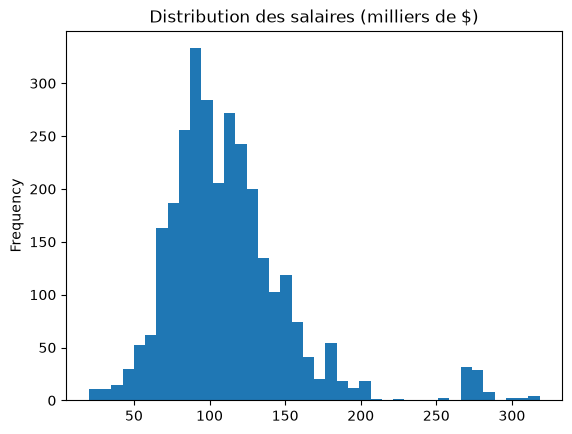

In [57]:
df["wage"].plot(kind="hist", bins=40, title="Distribution des salaires (milliers de $)");

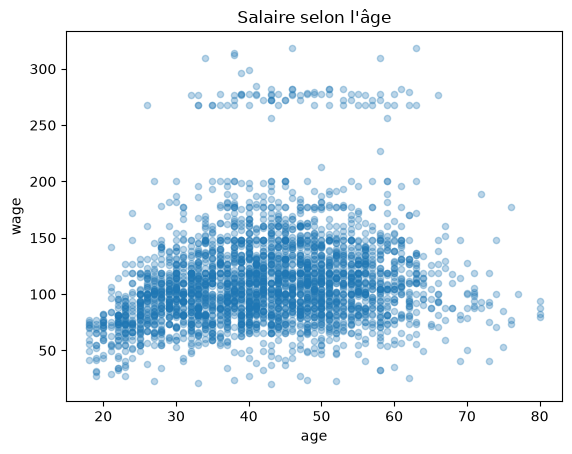

In [58]:
df.plot(kind="scatter", x="age", y="wage", alpha=0.3, title="Salaire selon l'âge");

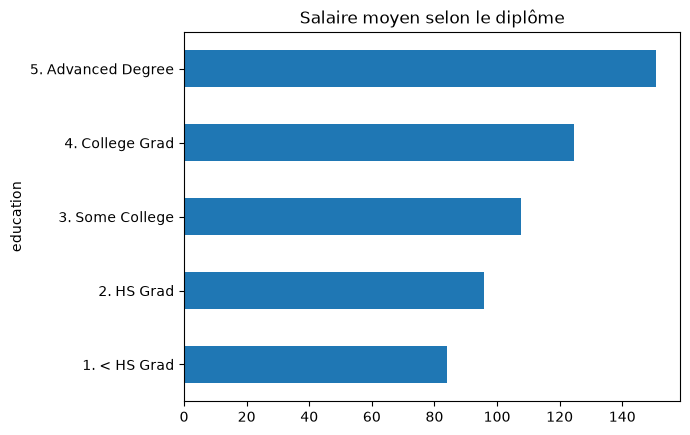

In [59]:
stats_educ["salaire_moyen"].plot(kind="barh", title="Salaire moyen selon le diplôme");

## 9. Exercice de synthèse : le jeu de données `Credit`

Le jeu de données `Credit` (package `ISLP`) décrit 400 détenteurs de cartes de crédit : revenu (`Income`, en milliers de dollars), plafond de crédit (`Limit`), score (`Rating`), nombre de cartes (`Cards`), âge (`Age`), années d'études (`Education`), propriétaire (`Own`), étudiant (`Student`), marié (`Married`), région (`Region`) et solde moyen de la carte (`Balance`, en $).

1. Chargez les données dans un objet `credit` avec `load_data("Credit")`. Affichez les dimensions, les types des colonnes et les 5 premières lignes.
2. Y a-t-il des valeurs manquantes ? Affichez les statistiques descriptives des variables numériques.
3. Combien d'individus ont un solde nul (`Balance == 0`) ? Quelle proportion cela représente-t-il ?
4. Créez une variable `taux_utilisation` égale à `Balance / Limit`, puis affichez les 5 individus ayant le taux le plus élevé (colonnes `Income`, `Limit`, `Balance`, `taux_utilisation`).
5. Créez une variable `classe_revenu` découpant `Income` en 3 classes : moins de 25, de 25 à 50, plus de 50 (milliers de $).
6. Calculez le solde moyen et le revenu moyen selon le statut d'étudiant (`Student`). Commentez.
7. Calculez le solde moyen croisé selon la région (en lignes) et la classe de revenu (en colonnes).
8. Construisez une table `regions` donnant le nom français de chaque région (`East` → Est, `West` → Ouest, `South` → Sud) et joignez-la à `credit`.

In [ ]:
# 1.
# À compléter

In [ ]:
# 2.
# À compléter

In [ ]:
# 3.
# À compléter

In [ ]:
# 4.
# À compléter

In [ ]:
# 5.
# À compléter

In [ ]:
# 6. Les étudiants ont en moyenne un solde nettement plus élevé, alors que leur revenu moyen est proche de celui des non-étudiants.
# À compléter

In [ ]:
# 7.
# À compléter

In [ ]:
# 8.
# À compléter

## Récapitulatif

| Objectif | Syntaxe |
|---|---|
| Aperçu | `df.head()`, `df.shape`, `df.info()`, `df.dtypes`, `df.describe()` |
| Effectifs d'une variable qualitative | `df["x"].value_counts(normalize=True)` |
| Sélection de colonnes | `df["x"]`, `df[["x", "y"]]` |
| Sélection par position / étiquette | `df.iloc[lignes, colonnes]`, `df.loc[lignes, colonnes]` |
| Filtre | `df[(df["x"] > 1) & (df["y"] == "a")]`, `df.query("x > 1")`, `df["x"].isin([...])` |
| Nouvelle variable | `df["z"] = ...`, `np.where()`, `pd.cut()`, `df.assign()` |
| Renommer / supprimer | `df.rename(columns={...})`, `df.drop(columns=[...])` |
| Trier | `df.sort_values("x", ascending=False)` |
| Valeurs manquantes | `df.isna().sum()`, `df.dropna()`, `df.fillna()` |
| Statistiques par groupe | `df.groupby("g")["x"].mean()`, `.agg(nom=("x", "fonction"))`, `.transform()` |
| Tableaux croisés | `pd.crosstab()`, `pd.pivot_table()` |
| Assembler | `pd.concat([df1, df2])`, `pd.merge(df1, df2, on="cle", how="left")` |
| Importer / exporter | `pd.read_csv()`, `pd.read_excel()`, `df.to_csv()` |